# Heart Disease Prediction
Can routine clinical measurements (age, blood pressure, cholesterol, an exercise ECG test…) tell us whether a patient has coronary heart disease? This notebook builds and compares classifiers on the classic **UCI Cleveland** dataset.

**Data:** 303 patients, 13 features. **Target:** heart disease = more than 50% narrowing of a major vessel.  
**Metric:** ROC-AUC, plus precision / recall for the disease class.

> Educational project — not a diagnostic tool.

In [1]:
import urllib.request
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     GridSearchCV, cross_validate)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay
sns.set_theme(style='whitegrid'); SEED = 42

def fetch(url, name):
    path = Path('data') / name
    if not path.exists():
        path.parent.mkdir(exist_ok=True)
        urllib.request.urlretrieve(url, path)
    return path

## 1. Load the data and check the coding
The popular CSV version of this dataset stores every category as an integer code, and its documentation is known to be unreliable. Before modelling, I matched each row against the **original UCI file** to find out what the codes really mean.

In [2]:
raw = pd.read_csv(fetch('https://raw.githubusercontent.com/kb22/Heart-Disease-Prediction/master/dataset.csv',
                        'heart.csv'), encoding='utf-8-sig')
uci = pd.read_csv(fetch('https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data',
                        'processed.cleveland.data'), header=None, na_values='?',
                  names=list(raw.columns[:-1]) + ['num'])
print(raw.shape, uci.shape)
m = raw.merge(uci, on=['age', 'sex', 'trestbps', 'chol', 'thalach', 'oldpeak'], suffixes=('', '_uci'))
print('Rows matched:', len(m))
pd.crosstab(m['target'], m['num'], rownames=['target (CSV)'], colnames=['num (UCI: 0 = healthy)'])

(303, 14) (303, 14)
Rows matched: 303


num (UCI: 0 = healthy),0,1,2,3,4
target (CSV),,,,,
0,0,54,36,35,13
1,165,0,0,0,0


Every patient with `target = 1` has `num = 0` in the original file, i.e. **no** disease. The target is inverted, so I flip it. The same check gives the meaning of the other codes:

In [3]:
for c in ['cp', 'restecg', 'slope', 'thal']:
    print(c, dict(m.groupby(c)[c + '_uci'].first()))

cp {0: np.float64(4.0), 1: np.float64(2.0), 2: np.float64(3.0), 3: np.float64(1.0)}
restecg {0: np.float64(2.0), 1: np.float64(0.0), 2: np.float64(1.0)}
slope {0: np.float64(3.0), 1: np.float64(2.0), 2: np.float64(1.0)}
thal {0: np.float64(nan), 1: np.float64(6.0), 2: np.float64(3.0), 3: np.float64(7.0)}


UCI coding: `cp` 1 = typical angina, 2 = atypical, 3 = non-anginal, 4 = asymptomatic; `restecg` 0 = normal, 1 = ST-T abnormality, 2 = LV hypertrophy; `slope` 1 = up, 2 = flat, 3 = down; `thal` 3 = normal, 6 = fixed defect, 7 = reversible defect. Translating everything into words:

In [4]:
CODES = {
    'sex': {0: 'Female', 1: 'Male'},
    'cp': {0: 'Asymptomatic', 1: 'Atypical angina', 2: 'Non-anginal pain', 3: 'Typical angina'},
    'fbs': {0: 'No', 1: 'Yes'}, 'exang': {0: 'No', 1: 'Yes'},
    'restecg': {0: 'Left ventricular hypertrophy', 1: 'Normal', 2: 'ST-T wave abnormality'},
    'slope': {0: 'Downsloping', 1: 'Flat', 2: 'Upsloping'},
    'ca': {0: '0', 1: '1', 2: '2', 3: '3'},
    'thal': {1: 'Fixed defect', 2: 'Normal', 3: 'Reversible defect'},
}
RENAME = {'cp': 'chest_pain', 'trestbps': 'resting_bp', 'chol': 'cholesterol', 'fbs': 'high_fasting_sugar',
          'restecg': 'rest_ecg', 'thalach': 'max_heart_rate', 'exang': 'exercise_angina',
          'oldpeak': 'st_depression', 'slope': 'st_slope', 'ca': 'major_vessels', 'thal': 'thallium_test'}
df = raw.copy()
df['heart_disease'] = 1 - df.pop('target')
print('Missing codes  ca=4:', (df.ca == 4).sum(), ' thal=0:', (df.thal == 0).sum())
df.loc[df.ca == 4, 'ca'] = 0; df.loc[df.thal == 0, 'thal'] = 2     # fill 7 missing values with the mode
for col, mp in CODES.items():
    df[col] = df[col].map(mp)
df = df.rename(columns=RENAME)
NUM = ['age', 'resting_bp', 'cholesterol', 'max_heart_rate', 'st_depression']
df[NUM] = df[NUM].astype(float)
df.head()

Missing codes  ca=4: 5  thal=0: 2


,age,sex,chest_pain,resting_bp,cholesterol,high_fasting_sugar,rest_ecg,max_heart_rate,exercise_angina,st_depression,st_slope,major_vessels,thallium_test,heart_disease
0,63.0,Male,Typical angina,145.0,233.0,Yes,Left ventricular hypertrophy,150.0,No,2.3,Downsloping,0,Fixed defect,0
1,37.0,Male,Non-anginal pain,130.0,250.0,No,Normal,187.0,No,3.5,Downsloping,0,Normal,0
2,41.0,Female,Atypical angina,130.0,204.0,No,Left ventricular hypertrophy,172.0,No,1.4,Upsloping,0,Normal,0
3,56.0,Male,Atypical angina,120.0,236.0,No,Normal,178.0,No,0.8,Upsloping,0,Normal,0
4,57.0,Female,Asymptomatic,120.0,354.0,No,Normal,163.0,Yes,0.6,Upsloping,0,Normal,0


In [5]:
df['heart_disease'].value_counts(normalize=True).round(3)

heart_disease
0    0.545
1    0.455
Name: proportion, dtype: float64

The classes are fairly balanced (~45% disease).

## 2. Exploratory analysis

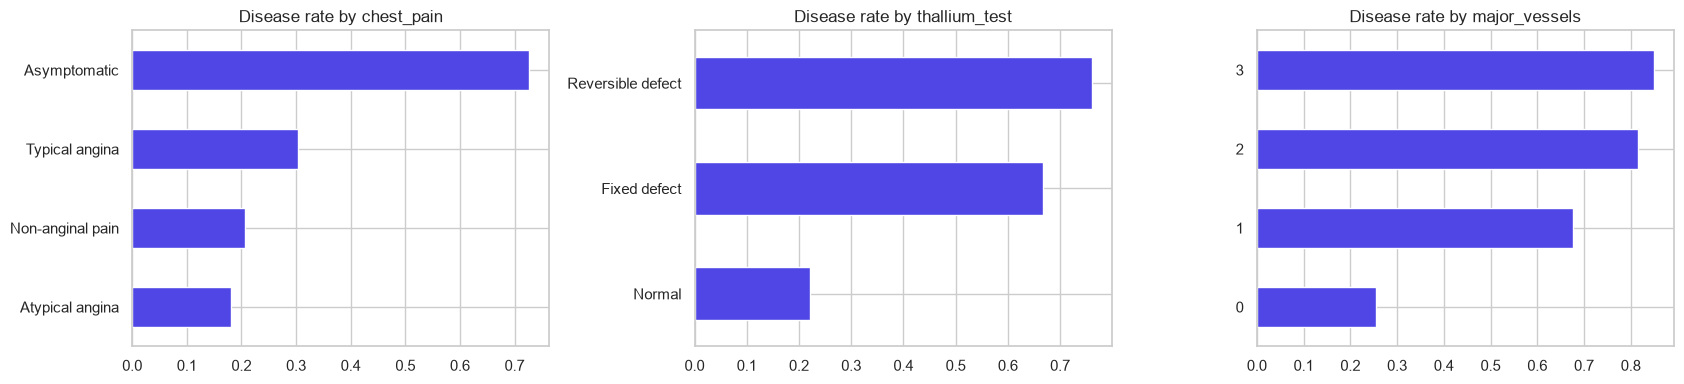

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, col in zip(axes, ['chest_pain', 'thallium_test', 'major_vessels']):
    df.groupby(col)['heart_disease'].mean().sort_values().plot.barh(ax=ax, color='#4f46e5')
    ax.set_title(f'Disease rate by {col}'); ax.set_ylabel('')
plt.tight_layout()

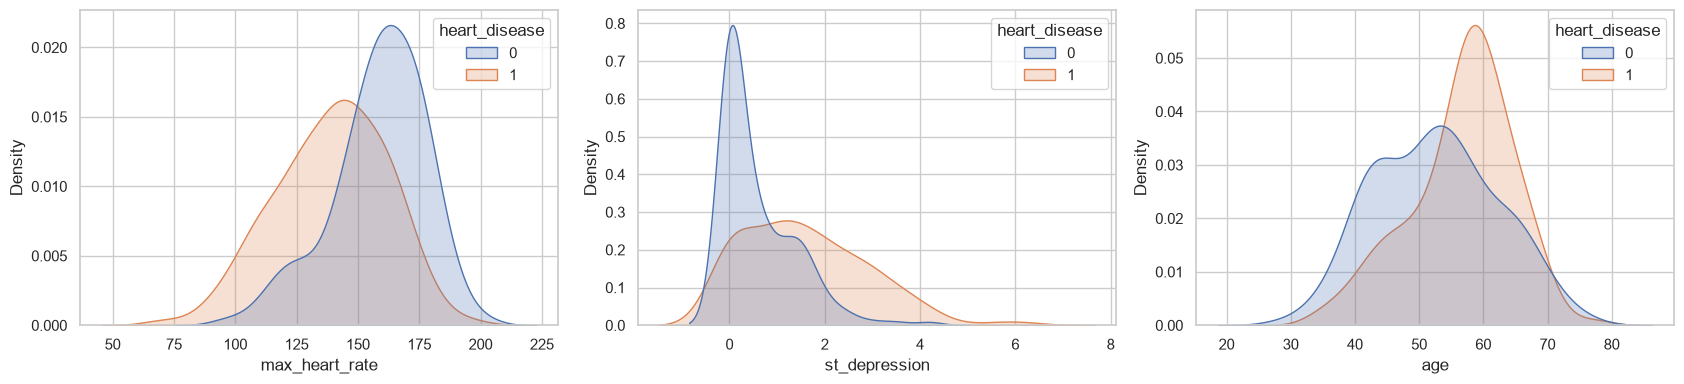

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, col in zip(axes, ['max_heart_rate', 'st_depression', 'age']):
    sns.kdeplot(data=df, x=col, hue='heart_disease', common_norm=False, fill=True, ax=ax)
plt.tight_layout()

**Findings**
- Counter-intuitively, patients with *asymptomatic* chest pain were diagnosed most often — they were referred for other reasons, and typical angina is less specific than it sounds.
- A reversible or fixed defect on the thallium test and more blocked vessels on fluoroscopy are strong signals.
- Patients with disease reach a lower maximum heart rate and show more ST depression during exercise.

## 3. Modelling
With only 303 patients a single train/test split is noisy, so:
- 20% is held out as a final test set (used once);
- models are compared on the training set with **5×5 repeated stratified CV**;
- the decision tree is tuned with `GridSearchCV` **inside** each CV fold (nested CV), so its score is not optimistic.

In [8]:
X, y = df.drop(columns='heart_disease'), df['heart_disease']
CAT = [c for c in X.columns if c not in NUM]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

prep = ColumnTransformer([('num', StandardScaler(), NUM), ('cat', OneHotEncoder(handle_unknown='ignore'), CAT)])
tree_search = GridSearchCV(
    Pipeline([('prep', prep), ('model', DecisionTreeClassifier(random_state=SEED))]),
    {'model__criterion': ['gini', 'entropy'], 'model__max_depth': [2, 3, 4, 5, 6],
     'model__min_samples_leaf': [1, 5, 10, 20]},
    cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring='roc_auc', n_jobs=2)
models = {
    'Logistic Regression': Pipeline([('prep', prep), ('model', LogisticRegression(max_iter=2000, C=0.3))]),
    'Decision Tree (tuned)': tree_search,
    'Random Forest': Pipeline([('prep', prep), ('model', RandomForestClassifier(
        n_estimators=400, min_samples_leaf=3, max_features='sqrt', random_state=SEED, n_jobs=-1))]),
}
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)
rows = []
for name, mdl in models.items():
    r = cross_validate(mdl, X_train, y_train, cv=cv, scoring=['roc_auc', 'f1', 'accuracy'], n_jobs=2)
    rows.append({'model': name, **{k: r[f'test_{k}'].mean() for k in ['roc_auc', 'f1', 'accuracy']},
                 'roc_auc_std': r['test_roc_auc'].std()})
pd.DataFrame(rows).sort_values('roc_auc', ascending=False).round(3)

,model,roc_auc,f1,accuracy,roc_auc_std
0,Logistic Regression,0.916,0.829,0.850,0.036
2,Random Forest,0.913,0.807,0.825,0.026
1,Decision Tree (tuned),0.840,0.733,0.765,0.043


Logistic Regression and Random Forest are equally good; the single tree is clearly worse (it can only make a few coarse splits on 240 patients). Logistic Regression is the simplest, so it is the final model. The tree is still worth a look because it turns the data into readable rules.

### The tuned decision tree

Best parameters: {'model__criterion': 'gini', 'model__max_depth': 4, 'model__min_samples_leaf': 20}
Depth: 4  leaves: 9


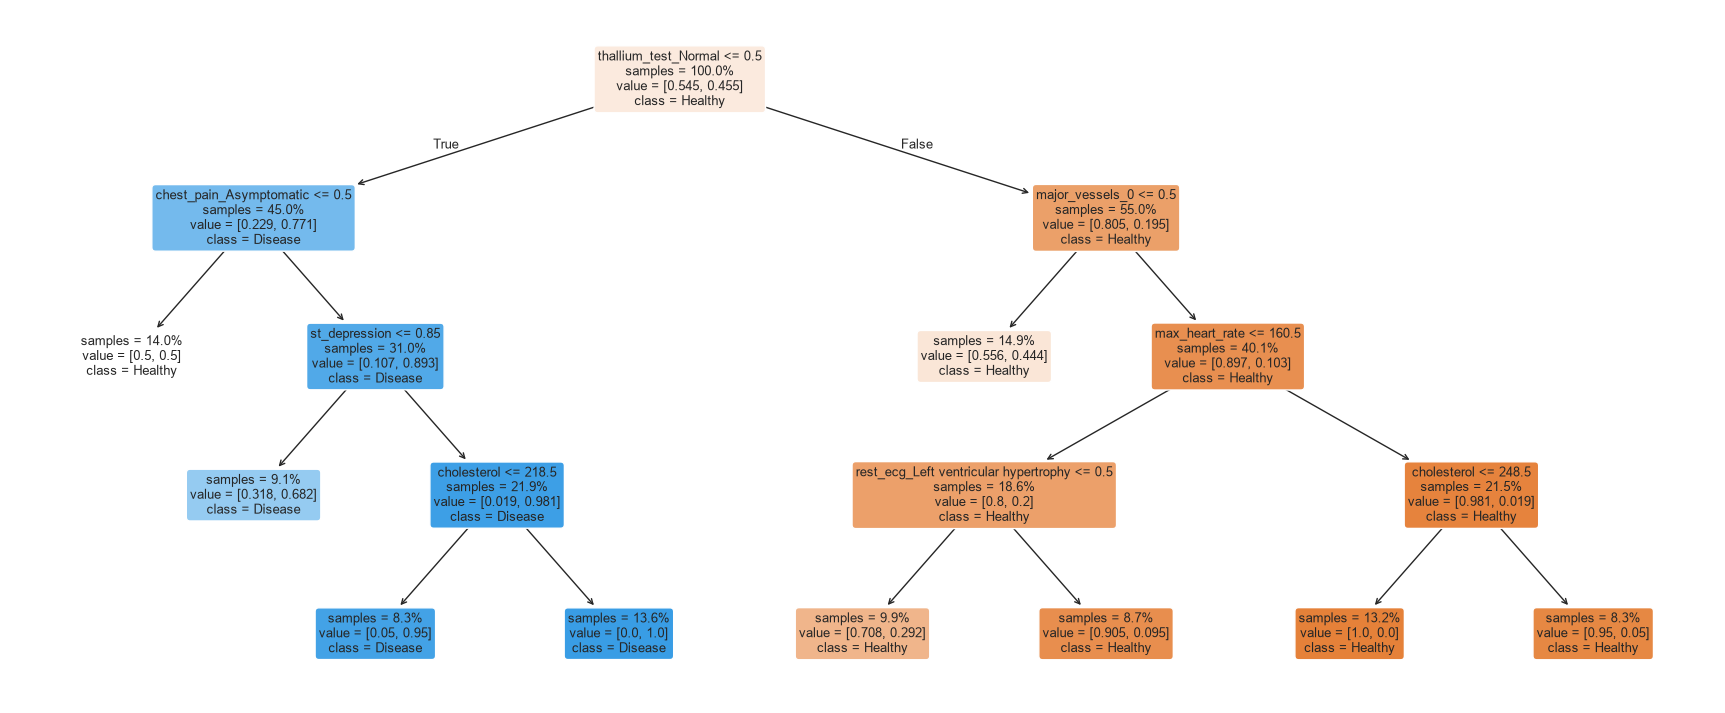

In [9]:
tree_search.fit(X_train, y_train)
print('Best parameters:', tree_search.best_params_)
tree = tree_search.best_estimator_
print('Depth:', tree.named_steps['model'].get_depth(), ' leaves:', tree.named_steps['model'].get_n_leaves())
# refit the same tree on unscaled numbers so the thresholds are in real units
raw_prep = ColumnTransformer([('num', 'passthrough', NUM), ('cat', OneHotEncoder(handle_unknown='ignore'), CAT)])
params = {k.replace('model__', ''): v for k, v in tree_search.best_params_.items()}
tree_plot = Pipeline([('prep', raw_prep), ('model', DecisionTreeClassifier(random_state=SEED, **params))]).fit(X_train, y_train)
names = [n.split('__', 1)[1] for n in tree_plot.named_steps['prep'].get_feature_names_out()]
plt.figure(figsize=(22, 9))
plot_tree(tree_plot.named_steps['model'], feature_names=names, class_names=['Healthy', 'Disease'],
          filled=True, rounded=True, impurity=False, proportion=True, fontsize=9);

In [10]:
print(export_text(tree_plot.named_steps['model'], feature_names=names))

|--- thallium_test_Normal <= 0.50
|   |--- chest_pain_Asymptomatic <= 0.50
|   |   |--- class: 0
|   |--- chest_pain_Asymptomatic >  0.50
|   |   |--- st_depression <= 0.85
|   |   |   |--- class: 1
|   |   |--- st_depression >  0.85
|   |   |   |--- cholesterol <= 218.50
|   |   |   |   |--- class: 1
|   |   |   |--- cholesterol >  218.50
|   |   |   |   |--- class: 1
|--- thallium_test_Normal >  0.50
|   |--- major_vessels_0 <= 0.50
|   |   |--- class: 0
|   |--- major_vessels_0 >  0.50
|   |   |--- max_heart_rate <= 160.50
|   |   |   |--- rest_ecg_Left ventricular hypertrophy <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- rest_ecg_Left ventricular hypertrophy >  0.50
|   |   |   |   |--- class: 0
|   |   |--- max_heart_rate >  160.50
|   |   |   |--- cholesterol <= 248.50
|   |   |   |   |--- class: 0
|   |   |   |--- cholesterol >  248.50
|   |   |   |   |--- class: 0



The root split is the thallium stress test: a normal result sends most patients to the healthy side. Then chest-pain type, blocked vessels and ST depression refine the decision — similar to how a cardiologist reasons.

## 4. Final evaluation on the test set

In [11]:
final = models['Logistic Regression'].fit(X_train, y_train)
proba = final.predict_proba(X_test)[:, 1]
print('Logistic Regression test ROC-AUC:', round(roc_auc_score(y_test, proba), 3))
print('Decision tree test ROC-AUC:     ', round(roc_auc_score(y_test, tree.predict_proba(X_test)[:, 1]), 3))
print(classification_report(y_test, proba >= 0.5, target_names=['Healthy', 'Disease']))

Logistic Regression test ROC-AUC: 0.936
Decision tree test ROC-AUC:      0.808
              precision    recall  f1-score   support

     Healthy       0.83      0.88      0.85        33
     Disease       0.85      0.79      0.81        28

    accuracy                           0.84        61
   macro avg       0.84      0.83      0.83        61
weighted avg       0.84      0.84      0.84        61



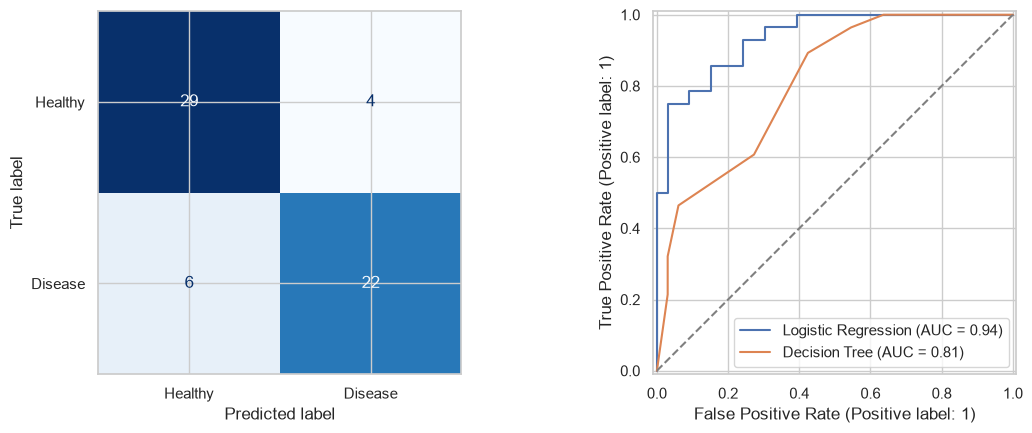

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, proba >= 0.5, display_labels=['Healthy', 'Disease'],
                                        cmap='Blues', colorbar=False, ax=axes[0])
RocCurveDisplay.from_predictions(y_test, proba, name='Logistic Regression', ax=axes[1])
RocCurveDisplay.from_predictions(y_test, tree.predict_proba(X_test)[:, 1], name='Decision Tree', ax=axes[1])
axes[1].plot([0, 1], [0, 1], '--', color='grey'); plt.tight_layout()

The test set has only 61 patients, so these numbers have wide error bars (one patient ≈ 1.6% accuracy); the cross-validation table above is the more reliable comparison.

### Missing a sick patient is worse than a false alarm
For a screening tool, recall matters more. Lowering the threshold trades precision for recall:

In [13]:
from sklearn.metrics import precision_score, recall_score
pd.DataFrame([{'threshold': t, 'precision': precision_score(y_test, proba >= t),
               'recall': recall_score(y_test, proba >= t)} for t in [0.3, 0.4, 0.5, 0.6]]).round(3)

,threshold,precision,recall
0,0.3,0.743,0.929
1,0.4,0.815,0.786
2,0.5,0.846,0.786
3,0.6,0.875,0.750


### What drives the prediction

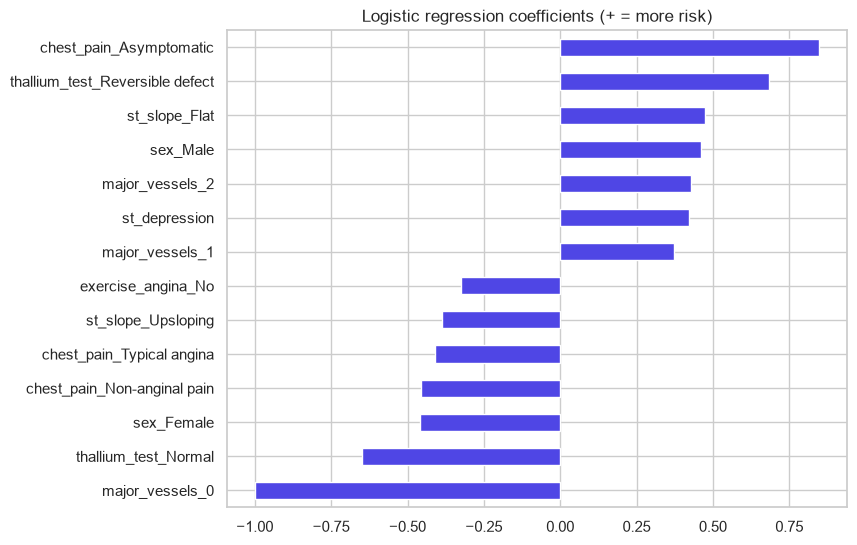

In [14]:
names = final.named_steps['prep'].get_feature_names_out()
coef = pd.Series(final.named_steps['model'].coef_[0], index=[n.split('__', 1)[1] for n in names]).sort_values()
pd.concat([coef.head(7), coef.tail(7)]).plot.barh(figsize=(8, 6.2), color='#4f46e5',
                                                 title='Logistic regression coefficients (+ = more risk)');

## 5. Conclusions
- A plain Logistic Regression ranks patients very well (CV ROC-AUC ≈ 0.92) and matches a Random Forest; a single tuned tree is weaker (≈ 0.84) but gives readable rules.
- Strongest signals: thallium test result, number of blocked vessels, chest-pain type, ST depression and max heart rate during exercise.
- Data-quality lesson: the widely shared CSV has an **inverted target** and undocumented codes — checking against the original source changed how every chart should be read.
- Limitations: 303 patients from one 1988 hospital study, so this is a learning project, **not medical advice**.

`train.py` contains the production version; the pipeline is exported to ONNX and runs in the web demo.